In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize
from itertools import product

In [24]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x > value), None)

def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

def compute_n_e(P, mu):
    """Compute number density (n_quad) and energy density (e_quad) from pressure (P) and chemical potential (mu)."""
    n_quad = gradient(P, mu)
    e_quad = (n_quad * mu[:-1]) - P[:-1]
    cs_quad = gradient(P[:-1],e_quad)
    return n_quad, e_quad, cs_quad

@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

from itertools import product
import numpy as np
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re

def find_valid_parameters(delta_P_arr, y_intersect, x_intersect, p_total, mu_total):
    A, B = [], []
    mu_c_h_arr, mu_c_q_arr = [], []
    P_c_h_arr, P_c_q_arr = [], []
    delta_P_found = []

    index = find_first_larger_index(p_total, y_intersect)
    #print(index)
    x1 = np.array(mu_total[:index])
    y1 = np.array(p_total[:index])

    x2 = np.array(mu_total[index:])
    y2 = np.array(p_total[index:])

    P_h_int_func = interpolate.interp1d(x1, y1, fill_value="extrapolate")
    P_q_int_func = interpolate.interp1d(x2, y2, fill_value="extrapolate")

    mu_start = mu_total[0]
    mu_end = mu_total[-1]

    mu_new = np.linspace(mu_start, mu_end, 2000)
    P_had_array = P_h_int_func(mu_new)
    P_quark_array = P_q_int_func(mu_new)
    #plt.plot(x1,y1)
    #plt.plot(x2,y2)
    #plt.show()
    #plt.plot(mu_new,P_had_array)
    #plt.plot(mu_new,P_quark_array)
    #plt.show()
    y_diff = np.abs(P_had_array - P_quark_array)

    for delta_P in delta_P_arr:
        found = False

        # Iterate through all combinations of mu_c_h and mu_c_q
        for mu_c_h, mu_c_q in product(mu_new, repeat=2):
            if found:
                break

            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            # Check if alpha is positive
            if alp <= 0:
                continue

            # Calculate the mixed phase pressure
            P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)

            # Split the pressure difference calculation
            min_idx = np.argmin(y_diff)
            m_h_P_diff = P_m[:min_idx] - P_had_array[:min_idx]
            m_q_P_diff = P_m[min_idx:] - P_quark_array[min_idx:]

            # Validate the pressure conditions
            if np.all(m_h_P_diff >= 0) and np.all(m_q_P_diff >= 0):
                #print(np.min(m_h_P_diff), np.min(m_q_P_diff))
                delta_P_found.append(delta_P)
                A.append(alp)
                B.append(bet)
                mu_c_h_arr.append(mu_c_h)
                mu_c_q_arr.append(mu_c_q)
                P_c_h_arr.append(P_h)
                P_c_q_arr.append(P_q)
                found = True

    print(f"Found {len(A)} valid sets of parameters.")
    return A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found

In [23]:
def mixed_phase(mu_total, p_total,n_total, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit, P_crit, delta_P_arr):
    P_arr_dp = []
    E_arr_dp = []
    number_density_dp = []
    mu_arr_dp = []

    for i in range(len(A)):
        index_1 = find_first_larger_index(mu_total, mu_c_h_arr[i])
        index_2 = find_first_larger_index(mu_total, mu_c_q_arr[i])

        mu_mixed = np.linspace(mu_total[index_1], mu_total[index_2], len(mu_total[index_1:index_2]))

        P_m = quad_P(mu_crit, mu_mixed, A[i], B[i], delta_P_arr[i], P_crit)
        P_had_half = p_total[:index_1]
        P_quark_half = p_total[index_2:]

        grad_had = n_total[:index_1]
        grad_m = gradient(P_m,mu_mixed)
        grad_quark = n_total[index_2:]

        mu_arr = np.concatenate((mu_total[:index_1], mu_mixed[:-1], mu_total[index_2:]))

        grad_dummy = np.concatenate((grad_had,grad_m,grad_quark))
        P_arr_dummy = np.concatenate((P_had_half,P_m[:-1],P_quark_half))

        e_dummy = (grad_dummy*mu_arr)-P_arr_dummy

        P_arr_dp.append(P_arr_dummy)
        E_arr_dp.append(e_dummy)
        number_density_dp.append(grad_dummy)
        mu_arr_dp.append(mu_arr)

    return P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp

In [44]:
def smoothness_eos(pressure, mu, number_density, p_crit, mu_crit):
    delta_P_arr = [0.03, 0.0325, 0.035, 0.0375, 0.04, 0.0425, 0.045, 0.0475, 0.05]
    delta_P_arr = [0.02, 0.04, 0.05]
    
    A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found = find_valid_parameters(delta_P_arr, p_crit, mu_crit, pressure, mu)
    P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = mixed_phase(mu, pressure, number_density, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit, p_crit, delta_P_arr)
    
    return P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp

In [45]:
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [46]:
g_quark = 3
n_quark = np.linspace(0.5344,2.3,1000)
p = 63.177
e = 318.26 + 253.89

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
m0_had = 939.56
K_had = 17906.60 

In [47]:
# Hadronic EOS
p_had = P_from_nb(n_had, K_had, Gam_had)
mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)
e_had = e_from_n(n_had, K_had, Gam_had, m0_had)
cs_had = np.gradient(p_had, e_had)

K_quark = p_had[-1] / (n_quark[0] ** g_quark)
e_mid = n_quark[0]*mu_had[-1] - p_had[-1]
m0_quark = (e_mid - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

# Quark EOS
p_quark = P_from_nb(n_quark, K_quark, g_quark)
mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)
cs_quark = np.gradient(p_quark, e_quark)

# Concatenate hadronic and quark data
e_combined = np.concatenate((e_had, e_quark))
p_combined = np.concatenate((p_had, p_quark))
mu_combined = np.concatenate((mu_had, mu_quark))
cs_combined = np.concatenate((cs_had, cs_quark))
n_combined = np.concatenate((n_had, n_quark))

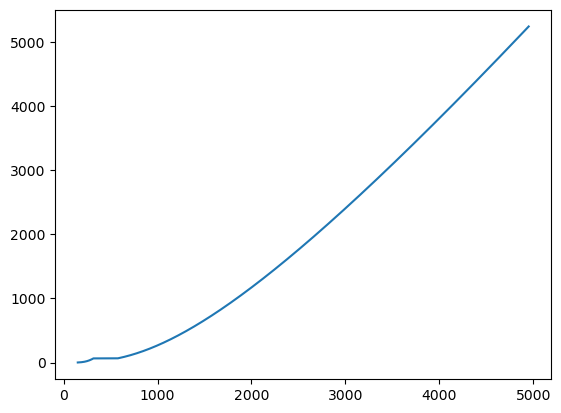

In [48]:
plt.plot(e_combined, p_combined)

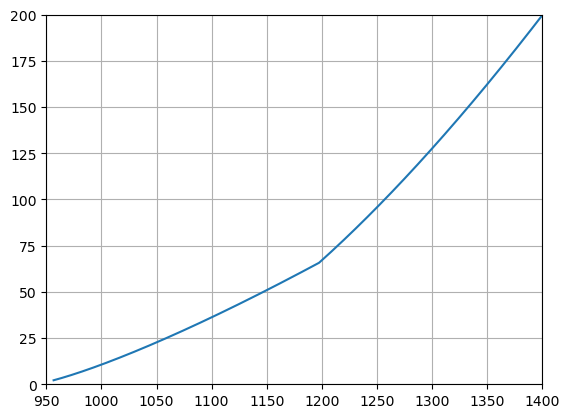

In [49]:
plt.plot(mu_combined, p_combined)
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.grid()
plt.show()

In [50]:
P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = smoothness_eos(pressure=p_combined, mu=mu_combined, number_density=n_combined, p_crit=p_had[-1], mu_crit=mu_had[-1])

Found 3 valid sets of parameters.


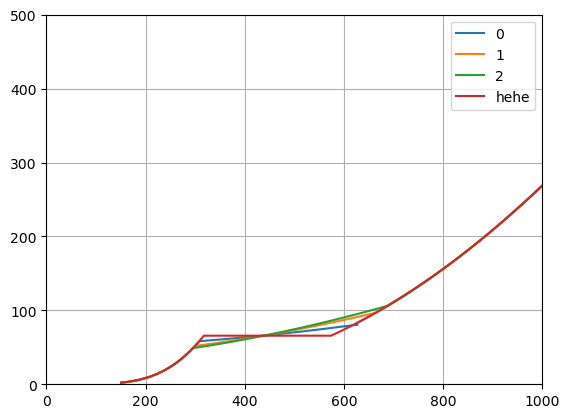

In [51]:
for i in range(len(P_arr_dp)):
    plt.plot(E_arr_dp[i], P_arr_dp[i], label=i)
plt.plot(e_combined, p_combined, label = 'hehe')
plt.xlim(0,1000)
plt.ylim(0,500)
plt.legend()
plt.grid()
plt.show() 

In [15]:
P_crit_1 = p_had[-1]*(1+0.01)
P_crit_2 = p_had[-1]*(1+0.3)
P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

In [16]:
b_optimal = []
a_optimal = []
P_optimal = []
min_distance_points = []
min_distances = []

for P in P_crit_new:
    # Define your points
    x1, y1 = mu_combined[0], p_combined[0]  # First point the curve must pass through
    x2, y2 = mu_had[-1], P  # Critical point

    # For inequality constraint defining hadronic part.
    x_values = np.array(mu_combined[1:])  # Hadronic part x_values
    f_values = np.array(p_combined[1:])   # Corresponding y_values

    # Define the quadratic function
    def quadratic(x, a, b):
        return a * (x - x2)**2 + b * (x - x2) + y2

    # Objective function: sum of squared differences (least distance point)
    def objective(params):
        a, b = params
        return 0

    # Initial guess for parameters
    initial_guess = [0, 0]

    # Constraint: quadratic must pass through the first point (x1, y1)
    def eq_constraint(params):
        a, b = params
        return quadratic(x1, a, b) - y1

    # Inequality constraint: ensure quadratic stays above hadronic part
    def ineq_constraint(params):
        a, b = params
        return quadratic(x_values, a, b) - f_values

    # Define the constraints
    constraints = [
        {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
        {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
    ]

    # Perform the optimization
    result = minimize(objective, initial_guess, constraints=constraints)

    if result.success:
        a_opt, b_opt = result.x

        # Find the least distance point
        min_distance = float('inf')
        closest_point = None

        # Calculate the quadratic value and find minimum distance
        for x, f in zip(x_values, f_values):
            y_quad = quadratic(x, a_opt, b_opt)
            distance = np.abs(y_quad - f)  # Only y-direction distance
            if distance < min_distance:
                min_distance = distance
                closest_point = (x, y_quad)

        # Save the optimal solution
        a_optimal.append(a_opt)
        b_optimal.append(b_opt)
        P_optimal.append(P)
        min_distance_points.append(closest_point)
        min_distances.append(min_distance)

    else:
        continue
# Convert min_distances to a NumPy array
min_distances = np.array(min_distances)

In [54]:
def concatenate_eos(P_max_points_1,mu_crit,P_all_1,p_total,mu_total,a_optimal_1,b_optimal_1,e_total,n_total):
    eos_final = []
    x2, y2 = mu_crit, P_all_1[0]  # Critical point
    a_op = a_optimal_1[0]
    b_op = b_optimal_1[0]        
    # Define quadratic function
    def quadratic(x):
        return a_op * (x - x2)**2 + b_op * (x - x2) + y2
    
    # Generate smooth quadratic fit until quark EOS
    index = find_first_larger_index(mu_total, P_max_points_1[0][0])
    mu_mixed = np.linspace(mu_total[0], mu_total[index], len(mu_total[:index]))
    p_fit = quadratic(mu_mixed)
    n_mix,e_mix,cs_mix = compute_n_e(p_fit, mu_mixed)
    
    e_t = np.concatenate((e_mix, e_total[index:]))
    #cs_t = np.concatenate((cs_mix, cs_total[i][index:]))
    p_t = np.concatenate((p_fit, p_total[index:]))
    mu_t = np.concatenate((mu_mixed, mu_total[index:]))

    #n_mix,e_t,cs_t = compute_n_e(p_t, mu_t)
    eos_final.append((p_t, mu_t, e_t))
    #print(index)
    #print(mu_mixed)
    #print(mu_total[i][index:])
    return eos_final

In [55]:
eos = concatenate_eos(min_distance_points,mu_had[-1],P_optimal,p_combined,mu_combined,a_optimal,b_optimal,e_combined,n_combined)

In [61]:
eos

[(array([2.17013897e+00, 2.24870878e+00, 2.32755847e+00, ...,
         5.21718780e+03, 5.22924257e+03, 5.24131589e+03]),
  array([ 956.58252996,  957.05043383,  957.51833771, ..., 4420.62238412,
         4425.86963561, 4431.12092386]),
  array([ 158.45795591,  159.03042732,  159.60317862, ..., 4934.61795404,
         4942.4354541 , 4950.26223155]))]

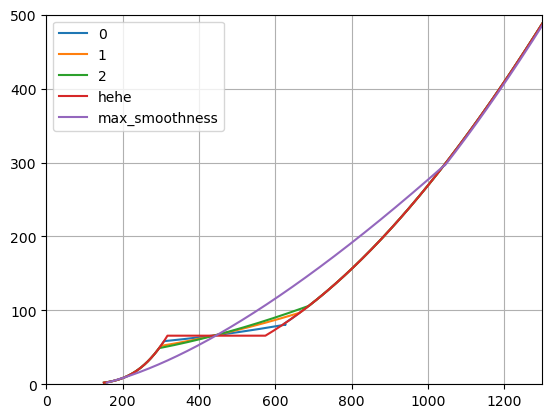

In [65]:
for i in range(len(P_arr_dp)):
    plt.plot(E_arr_dp[i], P_arr_dp[i], label=i)
plt.plot(e_combined, p_combined, label = 'hehe')
plt.plot(eos[0][2], eos[0][0][:-1], label = "max_smoothness")
plt.xlim(0,1300)
plt.ylim(0,500)
plt.legend()
plt.grid()
plt.show() 